# Credit Scoring Capstone
## Notebook 05 — Model Explainability

This notebook investigates the factors influencing predicted default risk
using SHAP (SHapley Additive exPlanations).

### Objectives

- Load the trained XGBoost model
- Reconstruct the held-out test dataset
- Prepare a sample for SHAP analysis
- Calculate SHAP values
- Identify globally important credit-risk features
- Examine how individual features influence model predictions
- Generate borrower-level explanations

## 2. Explainability in Credit Scoring

Predictive performance alone does not explain why a credit-scoring model
assigns a borrower a particular level of risk.

SHAP is used to examine how individual input features contribute to the
output of the XGBoost model.

For a particular prediction, SHAP decomposes the model output into a baseline
value and feature-level contributions:

\[
f(x) = E[f(X)] + \sum_{j=1}^{p}\phi_j
\]

where:

- \(E[f(X)]\) is the model's baseline output
- \(\phi_j\) is the SHAP contribution of feature \(j\)
- positive contributions push the model output upward
- negative contributions push the model output downward

SHAP therefore provides both global explanations of model behaviour and
local explanations for individual borrowers.

SHAP values describe associations learned by the predictive model and should
not be interpreted as causal effects.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from pathlib import Path

In [5]:
print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [7]:
df = pd.read_csv(
    "../data/application_clean.csv"
)

print(
    "Dataset shape:",
    df.shape
)

Dataset shape: (307511, 125)


In [9]:
exclude_features = [
    "SK_ID_CURR",
    "TARGET",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

X = df.drop(
    columns=exclude_features
)

y = df["TARGET"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 121)
y shape: (307511,)


In [11]:
split_indices = pd.read_csv(
    "../data/split_indices.csv"
)

test_idx = split_indices.loc[
    split_indices["split"] == "test",
    "index"
].values

X_test = X.loc[
    test_idx
].copy()

y_test = y.loc[
    test_idx
].copy()

print(
    "Test shape:",
    X_test.shape
)

print(
    "Test default rate:",
    y_test.mean()
)

Test shape: (46127, 121)
Test default rate: 0.08073362672621241


In [13]:
xgb_pipeline = joblib.load(
    "../models/xgb_pipeline.joblib"
)

xgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](121,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'DAYS_EMPLOYED_ANOM','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,121
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

In [15]:
xgb_preprocessor = (
    xgb_pipeline.named_steps[
        "preprocessor"
    ]
)

xgb_model = (
    xgb_pipeline.named_steps[
        "model"
    ]
)

In [17]:
print(
    type(xgb_preprocessor)
)

print(
    type(xgb_model)
)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBClassifier'>


In [19]:
feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names)
)

feature_names[:20]

Number of transformed features: 251


array(['num__CNT_CHILDREN', 'num__AMT_INCOME_TOTAL', 'num__AMT_CREDIT',
       'num__AMT_ANNUITY', 'num__AMT_GOODS_PRICE',
       'num__REGION_POPULATION_RELATIVE', 'num__DAYS_REGISTRATION',
       'num__DAYS_ID_PUBLISH', 'num__OWN_CAR_AGE', 'num__FLAG_MOBIL',
       'num__FLAG_EMP_PHONE', 'num__FLAG_WORK_PHONE',
       'num__FLAG_CONT_MOBILE', 'num__FLAG_PHONE', 'num__FLAG_EMAIL',
       'num__CNT_FAM_MEMBERS', 'num__REGION_RATING_CLIENT',
       'num__REGION_RATING_CLIENT_W_CITY', 'num__HOUR_APPR_PROCESS_START',
       'num__REG_REGION_NOT_LIVE_REGION'], dtype=object)

In [21]:
shap_sample = X_test.sample(
    n=2000,
    random_state=42
)

print(
    "SHAP sample shape:",
    shap_sample.shape
)

SHAP sample shape: (2000, 121)


In [23]:
X_shap_transformed = (
    xgb_preprocessor
    .transform(shap_sample)
)

print(
    "Transformed SHAP shape:",
    X_shap_transformed.shape
)

Transformed SHAP shape: (2000, 251)


In [25]:
if hasattr(
    X_shap_transformed,
    "toarray"
):
    X_shap_transformed = (
        X_shap_transformed.toarray()
    )

In [27]:
X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=shap_sample.index
)

print(
    "SHAP DataFrame shape:",
    X_shap_df.shape
)

X_shap_df.head()

SHAP DataFrame shape: (2000, 251)


,num__CNT_CHILDREN,num__AMT_INCOME_TOTAL,num__AMT_CREDIT,num__AMT_ANNUITY,num__AMT_GOODS_PRICE,num__REGION_POPULATION_RELATIVE,num__DAYS_REGISTRATION,num__DAYS_ID_PUBLISH,num__OWN_CAR_AGE,num__FLAG_MOBIL,...,cat__WALLSMATERIAL_MODE_Missing,cat__WALLSMATERIAL_MODE_Mixed,cat__WALLSMATERIAL_MODE_Monolithic,cat__WALLSMATERIAL_MODE_Others,cat__WALLSMATERIAL_MODE_Panel,"cat__WALLSMATERIAL_MODE_Stone, brick",cat__WALLSMATERIAL_MODE_Wooden,cat__EMERGENCYSTATE_MODE_Missing,cat__EMERGENCYSTATE_MODE_No,cat__EMERGENCYSTATE_MODE_Yes
88975,0.0,270000.0,545040.0,20677.5,450000.0,0.003541,-4011.0,-4009.0,2.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
247518,2.0,225000.0,983749.5,47326.5,864000.0,0.007020,-2239.0,-2528.0,13.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
303773,0.0,90000.0,900000.0,38133.0,900000.0,0.020713,-8449.0,-2906.0,9.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
29524,1.0,225000.0,2250000.0,59485.5,2250000.0,0.019689,-664.0,-1253.0,64.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
70565,0.0,180000.0,481176.0,21325.5,360000.0,0.018029,-3567.0,-1834.0,9.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [29]:
clean_feature_names = [
    name
    .replace("num__", "")
    .replace("cat__", "")
    for name in feature_names
]

X_shap_df.columns = (
    clean_feature_names
)

X_shap_df.columns[:20]

Index(['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
       'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_REGISTRATION',
       'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE',
       'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL',
       'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT',
       'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START',
       'REG_REGION_NOT_LIVE_REGION'],
      dtype='str')

In [31]:
explainer = shap.TreeExplainer(
    xgb_model
)

In [33]:
shap_values = explainer(
    X_shap_df
)

In [35]:
print(
    "SHAP values shape:",
    shap_values.values.shape
)

SHAP values shape: (2000, 251)


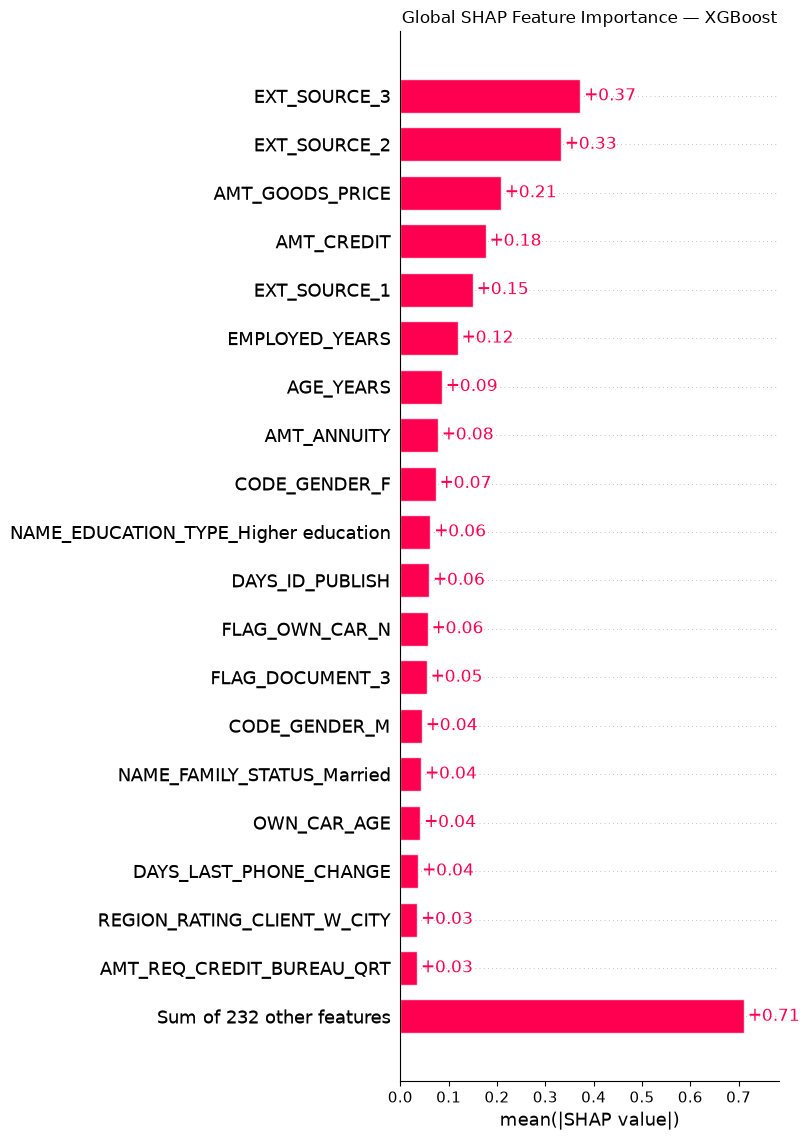

In [37]:
shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance — XGBoost"
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

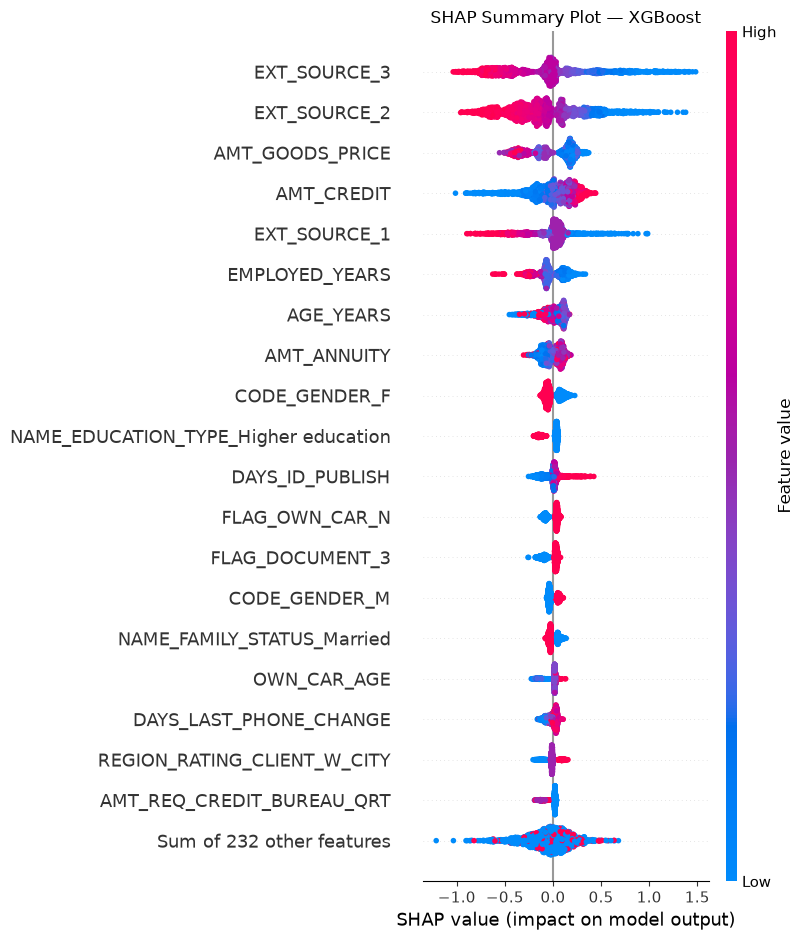

In [39]:
shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot — XGBoost"
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 14. Global SHAP Importance Table

Global feature importance is calculated using the mean absolute SHAP value
for each transformed feature.

A larger mean absolute SHAP value indicates that the feature has a greater
average influence on the XGBoost model output.

This measure describes predictive influence within the model and should not
be interpreted as a causal effect.

In [42]:
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": X_shap_df.columns,
    "Mean_Abs_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance.head(20)

,Feature,Mean_Abs_SHAP
0,EXT_SOURCE_3,0.372001
1,EXT_SOURCE_2,0.331959
2,AMT_GOODS_PRICE,0.207790
3,AMT_CREDIT,0.176444
4,EXT_SOURCE_1,0.149901
5,EMPLOYED_YEARS,0.118534
6,AGE_YEARS,0.085729
7,AMT_ANNUITY,0.077470
8,CODE_GENDER_F,0.072965
9,NAME_EDUCATION_TYPE_Higher education,0.061793


In [44]:
shap_importance.to_csv(
    "../outputs/shap_global_importance.csv",
    index=False
)

print(
    "SHAP importance table saved:",
    shap_importance.shape
)

SHAP importance table saved: (251, 2)


## 15. Interpreting SHAP Direction

SHAP values describe how individual features move the XGBoost model output
relative to its baseline prediction.

For the default-risk model:

\[
SHAP > 0
\]

indicates that the feature pushes the model output toward higher predicted
default risk, while:

\[
SHAP < 0
\]

indicates that the feature pushes the model output toward lower predicted
default risk.

The magnitude of the SHAP value represents the strength of the contribution.

These relationships represent patterns learned by the model rather than
causal relationships.

In [47]:
top_feature = (
    shap_importance
    .iloc[0]["Feature"]
)

print(
    "Most influential feature:",
    top_feature
)

Most influential feature: EXT_SOURCE_3


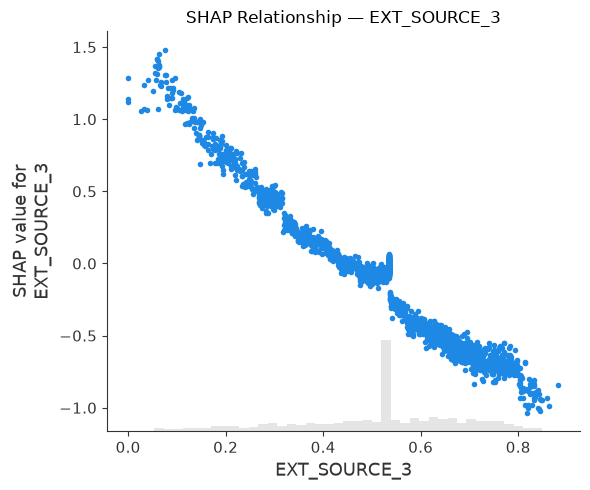

In [49]:
shap.plots.scatter(
    shap_values[:, top_feature],
    show=False
)

plt.title(
    f"SHAP Relationship — {top_feature}"
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_top_feature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 17. Local Borrower Explanation

In addition to global model behaviour, SHAP can explain the prediction for an
individual borrower.

A local explanation decomposes the model output into contributions from the
borrower's individual characteristics.

This allows the features pushing the prediction toward higher or lower
default risk to be identified for a particular case.

In [52]:
shap_sample_probability = (
    xgb_pipeline
    .predict_proba(shap_sample)[:, 1]
)

In [54]:
borrower_risk = pd.DataFrame({
    "index": shap_sample.index,
    "XGB_PD": shap_sample_probability
})

borrower_risk = borrower_risk.sort_values(
    "XGB_PD",
    ascending=False
)

borrower_risk.head(10)

,index,XGB_PD
1936,194770,0.637026
1772,8369,0.609452
618,228377,0.555341
378,119454,0.531398
582,5748,0.519826
820,42880,0.519463
1973,122972,0.512312
1621,113368,0.494352
125,214708,0.485880
279,239033,0.483620


In [56]:
high_risk_index = (
    borrower_risk
    .iloc[0]["index"]
)

high_risk_position = (
    shap_sample
    .index
    .get_loc(high_risk_index)
)

print(
    "Borrower index:",
    high_risk_index
)

print(
    "XGBoost predicted probability:",
    shap_sample_probability[
        high_risk_position
    ]
)

Borrower index: 194770.0
XGBoost predicted probability: 0.6370261


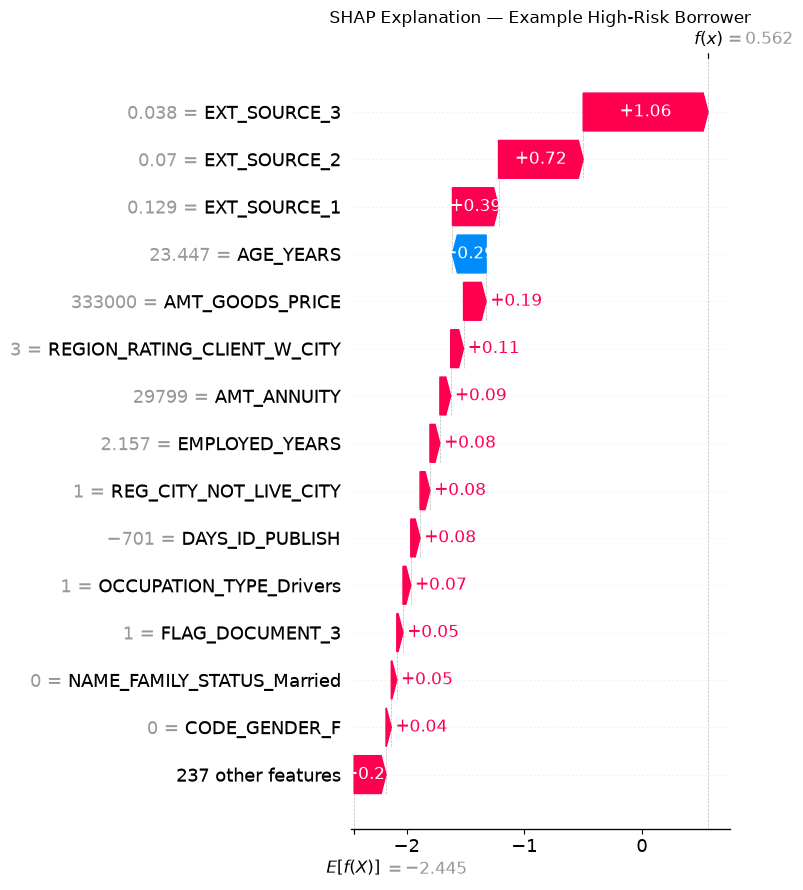

In [58]:
shap.plots.waterfall(
    shap_values[
        high_risk_position
    ],
    max_display=15,
    show=False
)

plt.title(
    "SHAP Explanation — Example High-Risk Borrower"
)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/shap_high_risk_borrower.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
borrower_shap = pd.DataFrame({
    "Feature": X_shap_df.columns,
    "Feature_Value":
        X_shap_df
        .iloc[high_risk_position]
        .values,

    "SHAP_Value":
        shap_values
        .values[
            high_risk_position
        ]
})

borrower_shap[
    "Abs_SHAP"
] = np.abs(
    borrower_shap[
        "SHAP_Value"
    ]
)

borrower_shap = (
    borrower_shap
    .sort_values(
        "Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

borrower_shap.head(15)

,Feature,Feature_Value,SHAP_Value,Abs_SHAP
0,EXT_SOURCE_3,0.038164,1.061231,1.061231
1,EXT_SOURCE_2,0.070057,0.719506,0.719506
2,EXT_SOURCE_1,0.128555,0.391258,0.391258
3,AGE_YEARS,23.446954,-0.285749,0.285749
4,AMT_GOODS_PRICE,333000.000000,0.191706,0.191706
5,REGION_RATING_CLIENT_W_CITY,3.000000,0.109138,0.109138
6,AMT_ANNUITY,29799.000000,0.091891,0.091891
7,EMPLOYED_YEARS,2.157426,0.084484,0.084484
8,REG_CITY_NOT_LIVE_CITY,1.000000,0.084198,0.084198
9,DAYS_ID_PUBLISH,-701.000000,0.078736,0.078736


In [62]:
borrower_shap.to_csv(
    "../outputs/shap_example_borrower.csv",
    index=False
)

## 21. Scope of the SHAP Explanation

SHAP analysis is applied to the XGBoost base learner rather than directly to
the complete stacked and calibrated framework.

XGBoost was selected for detailed explanation because it was the strongest
individual base learner in the model comparison and tree-based SHAP provides
an efficient method for examining its feature-level behaviour.

Therefore, the SHAP values explain how applicant characteristics influence
the XGBoost component of the framework. They should not be interpreted as an
exact decomposition of the final Isotonic-calibrated ensemble PD.

The analysis nevertheless provides insight into important predictive patterns
used by one of the principal components of the ensemble.

In [65]:
shap_importance.to_csv(
    "../outputs/shap_global_importance.csv",
    index=False
)

borrower_shap.to_csv(
    "../outputs/shap_example_borrower.csv",
    index=False
)

print(
    "Explainability outputs saved."
)

Explainability outputs saved.


In [67]:
shap_importance.head(20)

,Feature,Mean_Abs_SHAP
0,EXT_SOURCE_3,0.372001
1,EXT_SOURCE_2,0.331959
2,AMT_GOODS_PRICE,0.207790
3,AMT_CREDIT,0.176444
4,EXT_SOURCE_1,0.149901
5,EMPLOYED_YEARS,0.118534
6,AGE_YEARS,0.085729
7,AMT_ANNUITY,0.077470
8,CODE_GENDER_F,0.072965
9,NAME_EDUCATION_TYPE_Higher education,0.061793


## 23. Conclusion

This notebook examined the explainability of the XGBoost component of the
credit-scoring framework using SHAP.

Global SHAP analysis was used to identify the features with the greatest
average influence on XGBoost predictions. The SHAP beeswarm plot additionally
showed how different feature values contributed toward higher or lower
model-predicted default risk.

A local SHAP explanation was also generated for an example high-risk borrower,
demonstrating how individual applicant characteristics contributed to the
XGBoost model output.

The SHAP analysis provides insight into predictive relationships learned by
the model. These relationships should not be interpreted as causal effects.

Because SHAP was applied specifically to the XGBoost base learner, the
resulting explanations describe the behaviour of the XGBoost component rather
than providing an exact decomposition of the final stacked and
Isotonic-calibrated Probability of Default.